In [34]:
import os
import json
import numpy as np
import librosa
import pandas as pd
#import yaml
import matplotlib.pyplot as plt
import IPython
import soundfile as sf
from tqdm import tqdm 
from collections import OrderedDict
from sklearn.model_selection import train_test_split
import glob
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import CSVLogger, EarlyStopping, ModelCheckpoint
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

In [39]:
def plot_instrument_histogram(instrument_counts, top_n=20, min_count=None):
    """
    Creates a horizontal histogram with the frequencies of the instruments.
    
    Args:
        instrument_counts: Dictionary with instrument as key and frequency as value
        top_n: Show only the top N most frequent instruments (default 20)
        min_count: Minimum appearance threshold to include an instrument
    """
    # Sort instruments by frequency (highest to lowest)
    sorted_instruments = sorted(instrument_counts.items(), key=lambda x: x[1], reverse=True)
    
    # Filter according to parameters
    filtered_instruments = []
    for instrument, count in sorted_instruments:
        if min_count is not None and count < min_count:
            continue
        filtered_instruments.append((instrument, count))
        if len(filtered_instruments) >= top_n:
            break
    
    # Separate names and counts for the plot
    names = [item[0] for item in filtered_instruments]
    counts = [item[1] for item in filtered_instruments]
    
    # Create figure with size adapted to the number of instruments
    plt.figure(figsize=(16, max(8, len(names) * 0.3)))
    
    # Create horizontal bars
    plt.barh(names, counts, color='skyblue')
    
    # Add labels and title
    plt.xlabel('Number of appearances')
    plt.title('Instrument frequency in MedleyDB')
    
    # Adjust margins
    plt.tight_layout()
    
    # Add the numeric value at the end of each bar
    for i, count in enumerate(counts):
        plt.text(count + 0.5, i, str(count), va='center')
    
    # Show the plot
    plt.show()

In [27]:
# Final categories - Essential for interpreting the numeric indices
instrument_categories = [
    'electric_bass',
    'drum_set',
    'piano',
    'synthesizer',
    'clean_electric_guitar',
    'distorted_electric_guitar',
    'acoustic_guitar',
    'violin',
    'female_singer',
    'vocalists',
    'male_vocals',
    'other_bowed_strings',
    'woodwinds',
    'brass',
    'other_percussion',
    'other_plucked_strings',
    'reed_instruments',
    'fx_and_processed'
]

# Mapping from categories to indices - Useful if you need to convert names to indices
category_to_idx = {category: idx for idx, category in enumerate(instrument_categories)}

In [28]:
# Load pre-processed data
X = np.load(os.path.join('extracted_segments_features', 'processed_features_cqt.npy'))  # or cqt
y = np.load(os.path.join('extracted_segments_features', 'processed_labels.npy'))

# Split into train, validation, and test sets
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.1, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.2, random_state=42, stratify=y_temp
)

print(f"Loaded data: {X.shape}")

Loaded data: (68879, 96, 130)



Class distribution in the complete dataset:
  other_percussion: 9085 samples (13.2%)
  electric_bass: 6781 samples (9.8%)
  drum_set: 6300 samples (9.1%)
  piano: 5604 samples (8.1%)
  other_bowed_strings: 4946 samples (7.2%)
  clean_electric_guitar: 4790 samples (7.0%)
  synthesizer: 4711 samples (6.8%)
  other_plucked_strings: 3635 samples (5.3%)
  fx_and_processed: 3452 samples (5.0%)
  male_vocals: 3180 samples (4.6%)
  violin: 3010 samples (4.4%)
  distorted_electric_guitar: 2475 samples (3.6%)
  acoustic_guitar: 2452 samples (3.6%)
  female_singer: 2190 samples (3.2%)
  woodwinds: 1860 samples (2.7%)
  vocalists: 1565 samples (2.3%)
  reed_instruments: 1460 samples (2.1%)
  brass: 1383 samples (2.0%)


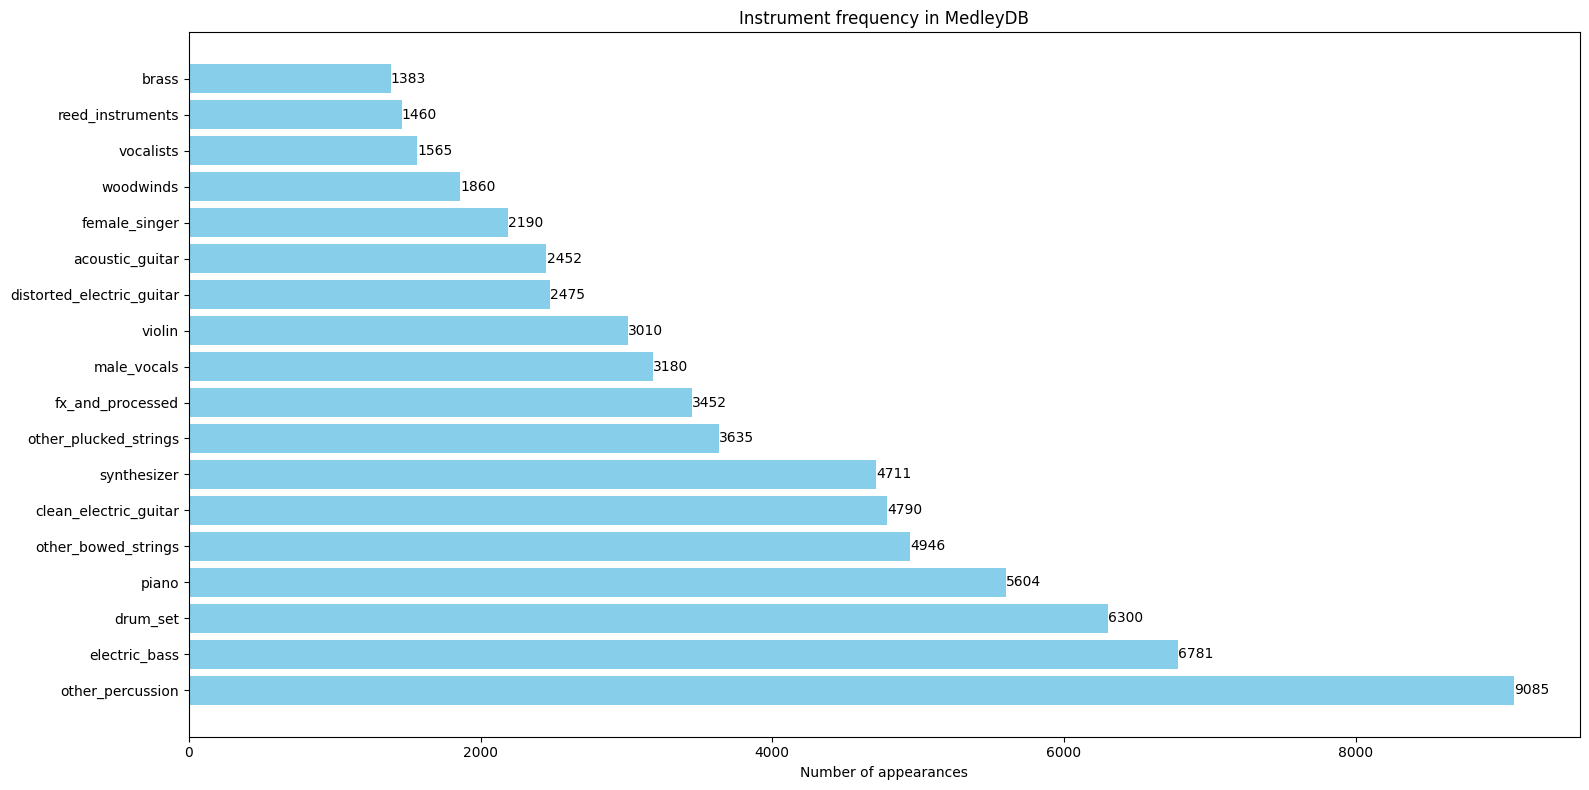


Dataset dimensions:
  Full data: (68879, 96, 130)
  Total number of samples: 68879
  Number of categories: 18


In [40]:
unique_classes, class_counts = np.unique(y, return_counts=True)

# Create a dictionary in the format {instrument: frequency}
instrument_counts = {}
for idx, count in zip(unique_classes, class_counts):
    category_name = instrument_categories[idx]
    instrument_counts[category_name] = count

# Show the distribution
print("\nClass distribution in the complete dataset:")
for category, count in sorted(instrument_counts.items(), key=lambda x: x[1], reverse=True):
    print(f"  {category}: {count} samples ({count/len(y)*100:.1f}%)")

plot_instrument_histogram(instrument_counts, top_n=len(instrument_categories))

print(f"\nDataset dimensions:")
print(f"  Full data: {X.shape}")
print(f"  Total number of samples: {len(y)}")
print(f"  Number of categories: {len(instrument_categories)}")

In [30]:
category_to_idx

{'electric_bass': 0,
 'drum_set': 1,
 'piano': 2,
 'synthesizer': 3,
 'clean_electric_guitar': 4,
 'distorted_electric_guitar': 5,
 'acoustic_guitar': 6,
 'violin': 7,
 'female_singer': 8,
 'vocalists': 9,
 'male_vocals': 10,
 'other_bowed_strings': 11,
 'woodwinds': 12,
 'brass': 13,
 'other_percussion': 14,
 'other_plucked_strings': 15,
 'reed_instruments': 16,
 'fx_and_processed': 17}

In [31]:
# 2D-CNN model for instrument classification
input_shape = [X_train.shape[1], X_train.shape[2], 1]
num_classes = len(instrument_categories)

model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=input_shape),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

c:\Users\Giuliano\Documents\STMAE\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 96, 130, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 96, 130, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 48, 65, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 48, 65, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 48, 65, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 24, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 24, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 24, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 12, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 24576)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │     3,145,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 18)             │         2,322 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,241,746 (12.37 MB)

 Trainable params: 3,241,298 (12.36 MB)

 Non-trainable params: 448 (1.75 KB)

In [22]:
# Callbacks for training
csv_logger = CSVLogger('training_model_stem.log', append=False)

early_stopping = EarlyStopping(monitor='val_loss', patience=100)

model_name = 'best_model_stem.h5'
model_checkpoint = ModelCheckpoint(model_name, monitor='val_accuracy', save_best_only=True, verbose=1)

callbacks = [csv_logger, early_stopping, model_checkpoint]

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=1000,
    batch_size=32,
    callbacks=callbacks
)

Epoch 1/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 198ms/step - accuracy: 0.3758 - loss: 2.2412
Epoch 1: val_accuracy improved from -inf to 0.63712, saving model to best_model_stem.h5


1722/1722 ━━━━━━━━━━━━━━━━━━━━ 355s 205ms/step - accuracy: 0.3758 - loss: 2.2409 - val_accuracy: 0.6371 - val_loss: 1.0785
Epoch 2/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 199ms/step - accuracy: 0.6644 - loss: 1.0277
Epoch 2: val_accuracy improved from 0.63712 to 0.83631, saving model to best_model_stem.h5


1722/1722 ━━━━━━━━━━━━━━━━━━━━ 354s 206ms/step - accuracy: 0.6644 - loss: 1.0276 - val_accuracy: 0.8363 - val_loss: 0.5343
Epoch 3/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step - accuracy: 0.7734 - loss: 0.6897
Epoch 3: val_accuracy improved from 0.83631 to 0.86077, saving model to best_model_stem.h5


1722/1722 ━━━━━━━━━━━━━━━━━━━━ 351s 204ms/step - accuracy: 0.7735 - loss: 0.6896 - val_accuracy: 0.8608 - val_loss: 0.4332
Epoch 4/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step - accuracy: 0.8202 - loss: 0.5405
Epoch 4: val_accuracy did not improve from 0.86077
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 351s 204ms/step - accuracy: 0.8202 - loss: 0.5405 - val_accuracy: 0.8015 - val_loss: 0.7552
Epoch 5/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step - accuracy: 0.8539 - loss: 0.4478
Epoch 5: val_accuracy improved from 0.86077 to 0.88727, saving model to best_model_stem.h5


1722/1722 ━━━━━━━━━━━━━━━━━━━━ 352s 205ms/step - accuracy: 0.8539 - loss: 0.4478 - val_accuracy: 0.8873 - val_loss: 0.3885
Epoch 6/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 196ms/step - accuracy: 0.8707 - loss: 0.3980
Epoch 6: val_accuracy did not improve from 0.88727
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 350s 204ms/step - accuracy: 0.8707 - loss: 0.3980 - val_accuracy: 0.8803 - val_loss: 0.4235
Epoch 7/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step - accuracy: 0.8909 - loss: 0.3441
Epoch 7: val_accuracy improved from 0.88727 to 0.92313, saving model to best_model_stem.h5


...

1722/1722 ━━━━━━━━━━━━━━━━━━━━ 362s 210ms/step - accuracy: 0.9663 - loss: 0.1031 - val_accuracy: 0.9604 - val_loss: 0.1664
Epoch 60/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 201ms/step - accuracy: 0.9625 - loss: 0.1149
Epoch 60: val_accuracy did not improve from 0.96037
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 359s 209ms/step - accuracy: 0.9625 - loss: 0.1149 - val_accuracy: 0.9581 - val_loss: 0.1897
Epoch 61/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.9656 - loss: 0.1038
Epoch 61: val_accuracy did not improve from 0.96037
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 362s 210ms/step - accuracy: 0.9656 - loss: 0.1038 - val_accuracy: 0.9541 - val_loss: 0.2167
Epoch 62/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.9662 - loss: 0.1037
Epoch 62: val_accuracy did not improve from 0.96037
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 360s 209ms/step - accuracy: 0.9662 - loss: 0.1037 - val_accuracy: 0.9308 - val_loss: 1.0977
Epoch 63/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.

1722/1722 ━━━━━━━━━━━━━━━━━━━━ 361s 210ms/step - accuracy: 0.9649 - loss: 0.1093 - val_accuracy: 0.9605 - val_loss: 0.1734
Epoch 65/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 201ms/step - accuracy: 0.9654 - loss: 0.1076
Epoch 65: val_accuracy did not improve from 0.96051
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 360s 209ms/step - accuracy: 0.9654 - loss: 0.1076 - val_accuracy: 0.9523 - val_loss: 0.2185
Epoch 66/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.9670 - loss: 0.0990
Epoch 66: val_accuracy did not improve from 0.96051
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 360s 209ms/step - accuracy: 0.9670 - loss: 0.0990 - val_accuracy: 0.9569 - val_loss: 0.2402
Epoch 67/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.9629 - loss: 0.1127
Epoch 67: val_accuracy did not improve from 0.96051
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 361s 210ms/step - accuracy: 0.9629 - loss: 0.1127 - val_accuracy: 0.9548 - val_loss: 0.2551
Epoch 68/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.

1722/1722 ━━━━━━━━━━━━━━━━━━━━ 374s 217ms/step - accuracy: 0.9676 - loss: 0.1008 - val_accuracy: 0.9609 - val_loss: 0.2507
Epoch 93/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step - accuracy: 0.9673 - loss: 0.1065
Epoch 93: val_accuracy did not improve from 0.96087
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 364s 212ms/step - accuracy: 0.9673 - loss: 0.1065 - val_accuracy: 0.9584 - val_loss: 0.1800
Epoch 94/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step - accuracy: 0.9680 - loss: 0.1016
Epoch 94: val_accuracy did not improve from 0.96087
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 365s 212ms/step - accuracy: 0.9680 - loss: 0.1016 - val_accuracy: 0.7279 - val_loss: 6.3730
Epoch 95/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step - accuracy: 0.9660 - loss: 0.1049
Epoch 95: val_accuracy did not improve from 0.96087
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 365s 212ms/step - accuracy: 0.9660 - loss: 0.1049 - val_accuracy: 0.9440 - val_loss: 0.2894
Epoch 96/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 205ms/step - accuracy: 0.

1722/1722 ━━━━━━━━━━━━━━━━━━━━ 371s 216ms/step - accuracy: 0.9679 - loss: 0.1074 - val_accuracy: 0.9611 - val_loss: 0.2034
Epoch 105/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 205ms/step - accuracy: 0.9685 - loss: 0.0998
Epoch 105: val_accuracy did not improve from 0.96109
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 366s 213ms/step - accuracy: 0.9685 - loss: 0.0998 - val_accuracy: 0.8587 - val_loss: 4.2234
Epoch 106/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 205ms/step - accuracy: 0.9672 - loss: 0.1056
Epoch 106: val_accuracy did not improve from 0.96109
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 367s 213ms/step - accuracy: 0.9672 - loss: 0.1056 - val_accuracy: 0.9525 - val_loss: 0.3648
Epoch 107/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 206ms/step - accuracy: 0.9675 - loss: 0.1076
Epoch 107: val_accuracy did not improve from 0.96109
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 368s 214ms/step - accuracy: 0.9675 - loss: 0.1076 - val_accuracy: 0.9570 - val_loss: 0.2007
Epoch 108/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 206ms/step - accur

1722/1722 ━━━━━━━━━━━━━━━━━━━━ 385s 224ms/step - accuracy: 0.9686 - loss: 0.0985 - val_accuracy: 0.9624 - val_loss: 0.2404


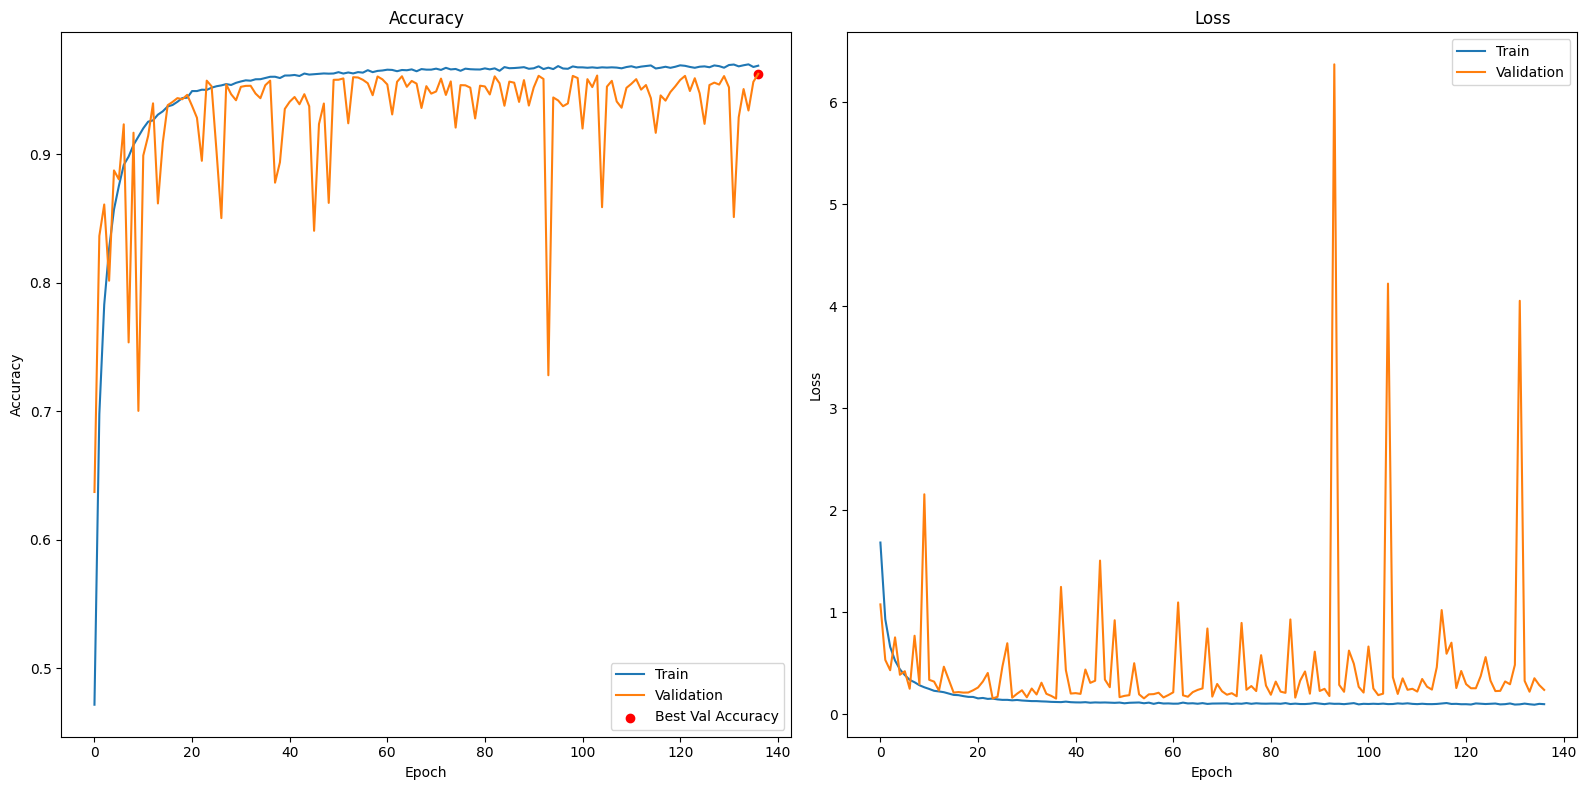

In [38]:
# History plot
log_df = pd.read_csv('training_model_stem.log')
best_val_acc = max(log_df['val_accuracy'])
best_val_acc_epoch = log_df['epoch'][log_df['val_accuracy'] == best_val_acc].values[0]

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(log_df['epoch'], log_df['accuracy'], label='Train')
plt.plot(log_df['epoch'], log_df['val_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch, best_val_acc, color='red', label='Best Val Accuracy')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df['epoch'], log_df['loss'], label='Train')
plt.plot(log_df['epoch'], log_df['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

388/388 ━━━━━━━━━━━━━━━━━━━━ 13s 33ms/step
216/216 ━━━━━━━━━━━━━━━━━━━━ 7s 32ms/step


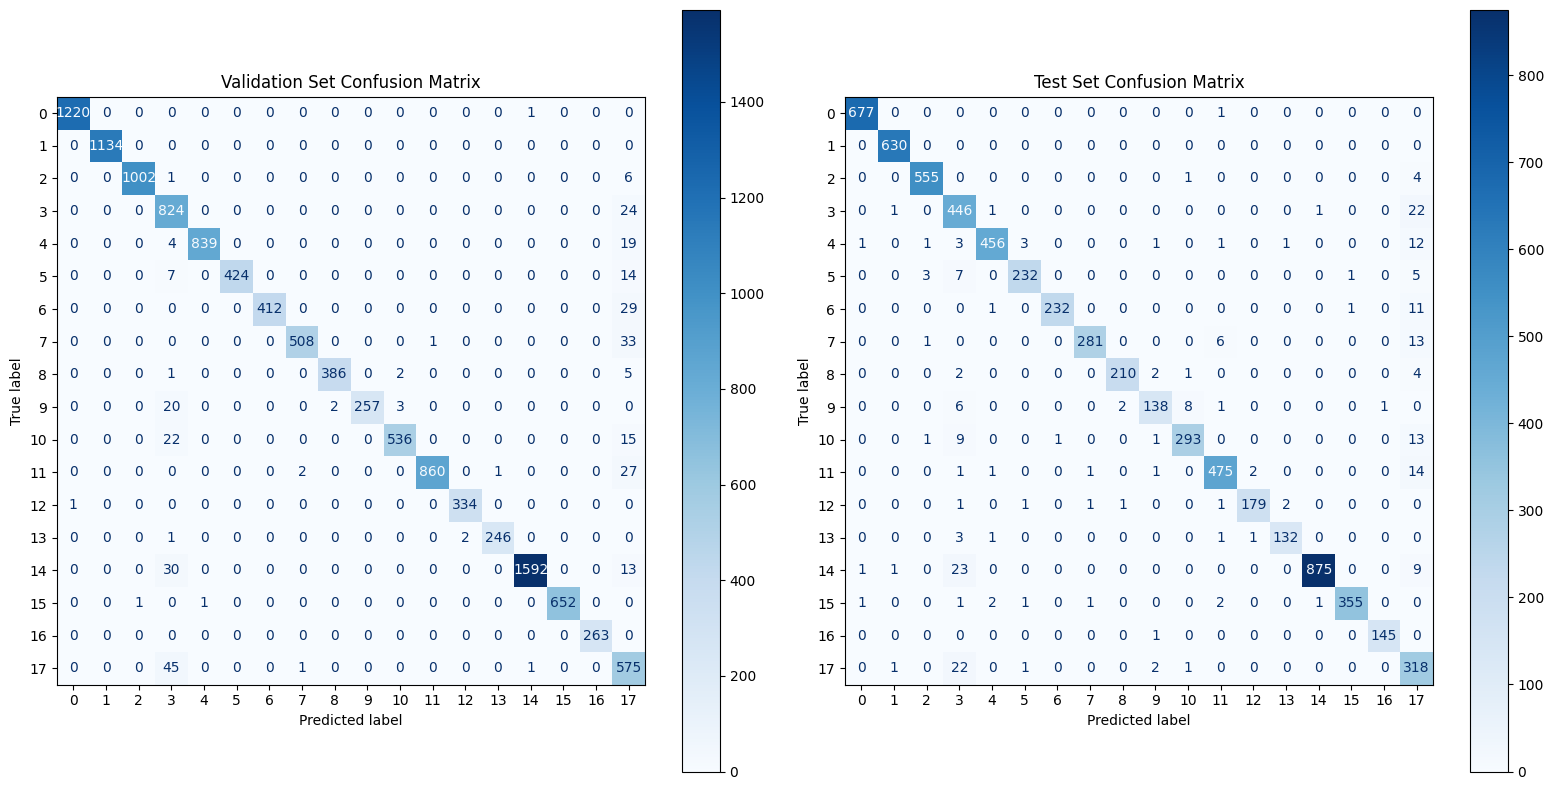

In [37]:
# Confusion matrix for validation and test sets
model.load_weights('best_model_stem.h5')

y_val_pred = model.predict(X_val).argmax(axis=1)
y_test_pred = model.predict(X_test).argmax(axis=1)

val_cm = confusion_matrix(y_val, y_val_pred)
test_cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(16, 8))

plt.subplot(1, 2, 1)
ConfusionMatrixDisplay(val_cm, display_labels=np.unique(y_train)).plot(cmap='Blues', ax=plt.gca())
plt.title("Validation Set Confusion Matrix")

plt.subplot(1, 2, 2)
ConfusionMatrixDisplay(test_cm, display_labels=np.unique(y_train)).plot(cmap='Blues', ax=plt.gca())
plt.title("Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

In [36]:
# Classification report for validation and test sets
print(classification_report(y_val, y_val_pred))
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1221
           1       1.00      1.00      1.00      1134
           2       1.00      0.99      1.00      1009
           3       0.86      0.97      0.91       848
           4       1.00      0.97      0.99       862
           5       1.00      0.95      0.98       445
           6       1.00      0.93      0.97       441
           7       0.99      0.94      0.96       542
           8       0.99      0.98      0.99       394
           9       1.00      0.91      0.95       282
          10       0.99      0.94      0.96       573
          11       1.00      0.97      0.98       890
          12       0.99      1.00      1.00       335
          13       1.00      0.99      0.99       249
          14       1.00      0.97      0.99      1635
          15       1.00      1.00      1.00       654
          16       1.00      1.00      1.00       263
          17       0.76    